<a href="https://colab.research.google.com/github/Deykuz/dsa107-labs/blob/main/Lab08_Utku_Zeyd_%C3%87%C4%B1nar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA 107 — Lab 8: Testing a claim

**Week 9 · w/c 23 November 2026** · paired with DSA 101 lecture week 8

**Name:** Utku Zeyd Çınar   **Student ID:** 26022121018

---

### What you will produce

A permutation test and a bootstrap confidence interval on the same real dataset, each with its distribution plotted and a conclusion written in plain language with no statistical jargon.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas matplotlib seaborn scikit-learn` in a new cell and try again.

### How to use this notebook

Every code cell that you fill in has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The **Graded:** line under each Goal shows exactly what earns the points, and every question shows how its points are shared. The table below shows how they add up to the 10 code points.

Some cells and lines are **already written for you** (*ready-made*). Read them, run them, and do not change them. Where you see `# TODO` or `...`, you write the code.

A code cell only shows the result of its **last line**. A value on any other line shows **nothing**. If you want to see two or more things from one cell, put each of them inside `print()`.

Most goals end with a **Check:** line. If your number is far from the check, fix your code before you go on.

**Random numbers and the seed.** The permutation cell in Part 3 starts with the ready-made line `rng = np.random.default_rng(8)`. The number in the brackets is a **seed**: it makes the "random" numbers the same every time. The bootstrap in Part 4 goes on with the same `rng`, so your numbers match the **Check:** lines best when you run the notebook **from the top** (Runtime → Run all). If you run a random cell twice, your numbers move a little. That is not a mistake.

The **Command reference** below holds the commands you need for this lab, and a few more. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| The observed statistic | Goal 2 | 1 |
| The permutation test | Goal 3a | 1.5 |
| The bootstrap | Goal 4a | 1.25 |
| Figures | Goals 3b, 4b (1 each — every figure needs an x label, a y label and a title) | 2 |
| On your own | Goal 5 | 1.25 |
| Interpretation | Q1 (0.5), Q2 (0.75), Q3 (0.5), Q4 (0.5), Q5 (0.75) | 3 |
| **Total** | | **10** |

**Rules for every part**

- Every figure needs an **x label**, a **y label** and a **title**.
- Every number in a written answer must be copied from **your own output**. If an earlier mistake gives you a wrong number, and you read that number correctly, you are not marked down a second time.
- A correct method with other commands also earns full points. Your random numbers may then be a little different from the **Check:** lines. That is not marked down, as long as your answers use your own numbers.
- Code that gives an error loses 0.25 for each cause of error.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series). `a` means an **array**: a list of numbers made by NumPy.
Not every command here is needed for this lab — choosing the right one is part of the work.

**Looking at the table and picking a group**

| Command | What it does |
| --- | --- |
| `df.head(n)` | returns the first `n` rows (5 if you do not say) |
| `df["col"].value_counts()` | every value of a column and how many times it appears |
| `df.groupby("g")["x"].agg(["count", "mean", "std"])` | the count, the mean and the SD of `x` in each group of `g` |
| `df[df["smoker"] == "Yes"]` | keeps only the rows where `smoker` is `"Yes"` (a boolean mask, Lab 3) |
| `df[df["smoker"] == "Yes"]["tip_pct"].values` | the `tip_pct` values of those rows, as a NumPy array (`.to_numpy()` does the same) |
| `df["day"].isin(["Sat", "Sun"])` | `True` for every row where `day` is `"Sat"` **or** `"Sun"` |
| `df[~mask]` | the `~` turns a mask around: keeps the rows where the mask is `False` |

**Numbers from an array**

| Command | What it does |
| --- | --- |
| `len(a)` | how many values there are |
| `a.mean()` / `a.std()` | the mean / the standard deviation (SD) |
| `a.min()` / `a.max()` | the smallest / the largest value |
| `round(x, 2)` | rounds **one** number to 2 decimal places |
| `print("mean:", round(a.mean(), 2))` | prints a label and a rounded number on one line |

**Arrays: joining, cutting and filling — new this week**

| Command | What it does |
| --- | --- |
| `np.concatenate([a, b])` | one array: all the values of `a`, then all the values of `b` |
| `a[:n]` | the **first** `n` values of `a` |
| `a[n:]` | every value **after** the first `n`, to the end. `a[:n]` and `a[n:]` together hold every value once |
| `np.empty(5000)` | an array with 5,000 places, ready to be filled (the values in it mean nothing until you fill them) |
| `a[i] = x` | puts `x` in place number `i` of the array `a` (the first place is number 0) |

**Random numbers**

| Command | What it does |
| --- | --- |
| `rng = np.random.default_rng(8)` | makes a random number generator called `rng`. The number in the brackets is the **seed**: the same seed gives the same "random" numbers every time |
| `rng.permutation(a)` | the **same values** as `a`, in a new random order: a **shuffle**. Nothing is added and nothing is lost |
| `rng.choice(a, size=len(a), replace=True)` | draws as many values as `a` has, at random, **with replacement**: the same value can be drawn again |
| `replace=False` | each value can be drawn only once (Lab 6) — with `size=len(a)` this is only a shuffle |

**Doing it many times: the `for` loop — from week 6**

| Command | What it does |
| --- | --- |
| `for i in range(n_reps):` | repeats the lines **under it** `n_reps` times. `i` is 0 the first time, then 1, 2, 3, … |
| 4 spaces at the start of a line | the lines **inside** the loop must start with 4 spaces (Colab adds them for you after the `:`) |
| `...` | does nothing; it only keeps an empty loop from giving an error. **Delete it** when you write your own lines |

**p-values and intervals — new this week**

| Command | What it does |
| --- | --- |
| `abs(x)` | the size of one number without its sign: `abs(-0.4)` is `0.4` |
| `np.abs(a)` | the same, for every value of an array |
| `np.mean(np.abs(a) >= abs(obs))` | the share of values of `a` that are at least as far from 0 as `obs`, on either side: a **two-sided** p-value |
| `(np.abs(a) >= abs(obs)).sum()` | **how many** values are that far from 0 |
| `np.mean(a >= obs)` | the share of values at least as big as `obs`: a **one-sided** p-value (not needed today) |
| `np.percentile(a, [2.5, 97.5])` | the two values that cut off the lowest 2.5% and the highest 2.5% of `a`: the two ends of the **middle 95%** |
| `lo, hi = np.percentile(a, [2.5, 97.5])` | the same, and it stores the two ends in two names, `lo` and `hi` |
| `hi - lo` | the width of the interval |

**Drawing and labelling**

| Command | What it does |
| --- | --- |
| `fig, ax = plt.subplots(figsize=(9, 4.5))` | makes an empty figure, 9 wide and 4.5 tall, and its axes `ax` |
| `ax.hist(a, bins=50)` | draws a histogram of the array `a` with 50 bars |
| `ax.axvline(x, color="red")` | draws a vertical red line at `x` |
| `ax.axvline(x, color="red", linestyle="--")` | the same, with a dashed line |
| `label="observed"` | add it inside `axvline(...)` to give the line a name … |
| `ax.legend()` | … and this shows the names of the lines in a small box |
| `ax.set_xlabel("...")` | names the horizontal axis |
| `ax.set_ylabel("...")` | names the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. The question

Do tables with a smoker tip a different percentage than tables without one?

Before any code: what would the world look like if the answer were *no*? It would look like a world in which the smoker label is irrelevant — you could shuffle the labels between tables and nothing would change. That thought is the entire test.

**The data.** The table is **restaurant tips**. One waiter wrote down **244 tables** (bills) that he served over a few months in **one restaurant** (Bryant & Smith, 1995). The money is in US dollars.

| Column | What it means |
| --- | --- |
| `total_bill` | the bill of the table, in dollars |
| `tip` | the tip, in dollars |
| `sex` | the sex of the person who paid the bill: `Female` or `Male` |
| `smoker` | `Yes` if someone at the table smoked, `No` if not |
| `day` | the day of the week: `Thur`, `Fri`, `Sat` or `Sun` |
| `time` | the meal: `Lunch` or `Dinner` |
| `size` | the number of people at the table |
| `tip_pct` | made by the ready-made cell below: the tip as a percentage of the bill (`100 * tip / total_bill`) |

> **Ready-made cell · 0 pt.** Do not change anything. Just run it. It loads the table as `tips`, makes the column `tip_pct`, and shows the number of tables, the mean and the SD of `tip_pct` for the smoker tables (`Yes`) and the non-smoker tables (`No`).

In [2]:
tips = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv")
tips["tip_pct"] = 100 * tips["tip"] / tips["total_bill"]
print(tips.groupby("smoker", observed=True)["tip_pct"]
      .agg(["count", "mean", "std"]).round(2))

        count   mean   std
smoker                    
No        151  15.93  3.99
Yes        93  16.32  8.51


**Q1 · 0.5 pt.** Write the null hypothesis as a sentence about the *process* that generated the data, not as a formula. Then write the alternative.

**Null hypothesis:** whether a table has a smoker plays no part in how much it tips. The same process produced the tip percentages of smoker and non-smoker tables, so the smoker label is just a tag that could be shuffled between tables without changing anything. Any gap between the two group means comes only from chance, from which tables happened to get the "Yes" label.

**Alternative hypothesis:** whether a table has a smoker is connected to how much it tips. Smoker tables and non-smoker tables tip a different percentage on average, in either direction (higher or lower), so the test is two-sided.

## 2. The observed statistic

The test statistic is whatever number captures the effect you are looking for. Here: the difference in mean tip percentage between the two groups.

> **Goal 2 · 1 pt.** Split the table into the two groups. Store the `tip_pct` values of the smoker tables (`smoker` is `"Yes"`) as an array called **`yes`**, and the `tip_pct` values of the non-smoker tables (`smoker` is `"No"`) as an array called **`no_`** (with `_` at the end). Use exactly these two names: the ready-made lines in Part 3 use them. Print the number of tables and the mean `tip_pct` of each group, rounded to 2 decimals. Then store the observed difference — the mean of `yes` **minus** the mean of `no_` — in a variable called **`observed`**, and print it rounded to 2 decimals. Store it **without** rounding.

In [3]:
# Goal 2 · 1 pt
# Smoker tables: keep the rows where smoker is "Yes", take tip_pct as a NumPy array
yes = tips[tips["smoker"] == "Yes"]["tip_pct"].values
# Non-smoker tables: the same for smoker == "No"
no_ = tips[tips["smoker"] == "No"]["tip_pct"].values

print("Smoker tables (Yes):", len(yes), "| mean tip %:", round(yes.mean(), 2))
print("Non-smoker tables (No):", len(no_), "| mean tip %:", round(no_.mean(), 2))

# Observed difference: smokers minus non-smokers, stored WITHOUT rounding
observed = yes.mean() - no_.mean()
print("Observed difference (Yes - No):", round(observed, 2))

Smoker tables (Yes): 93 | mean tip %: 16.32
Non-smoker tables (No): 151 | mean tip %: 15.93
Observed difference (Yes - No): 0.39


## 3. The permutation test

Pool everything, shuffle, split back into two groups of the original sizes, recompute the difference. That is one draw from the world where the label does not matter. Do it five thousand times.

> **Goal 3a · 1.5 pt.** The first lines of the cell are **ready-made** (down to `null_diffs = np.empty(n_reps)`): they set the seed, pool the two groups into one array `pooled`, store the size of the smoker group as `n_yes`, and make an empty array `null_diffs` with 5,000 places. Do not change them.
> Fill in the loop. **Inside** the loop (4 spaces at the start of each line), in place of `...`, write two lines:
> 1. shuffle `pooled` with `rng.permutation(pooled)` and store it as `shuffled`;
> 2. the first `n_yes` values of `shuffled` are the fake smoker group, and the rest are the fake non-smoker group. Put the difference of their means in place `i` of `null_diffs`: `null_diffs[i] = ...`.
>
> After the loop, compute the **p-value**: the share of the 5,000 shuffles whose difference is at least as far from 0 as `observed`, on **either** side (two-sided). Store it as **`p`** and print it, rounded to 4 decimals.

In [4]:
# Goal 3a · 1.5 pt
rng = np.random.default_rng(8)
pooled = np.concatenate([yes, no_])
n_yes = len(yes)
n_reps = 5000

null_diffs = np.empty(n_reps)
for i in range(n_reps):
    # Shuffle: same 244 values, new random order (labels no longer matter)
    shuffled = rng.permutation(pooled)
    # First n_yes values = fake smoker group, the rest = fake non-smoker group
    null_diffs[i] = shuffled[:n_yes].mean() - shuffled[n_yes:].mean()

# Two-sided p-value: share of shuffles at least as far from 0 as the observed difference
p = np.mean(np.abs(null_diffs) >= abs(observed))
print("p-value:", round(p, 4))

p-value: 0.6464


> **Goal 3b · Figure · 1 pt.** Plot the **null distribution**: a histogram of the 5,000 values in `null_diffs`, with 50 bars. Mark the observed value with a **vertical line** at `observed`. Give the figure an x label, a y label and a title.

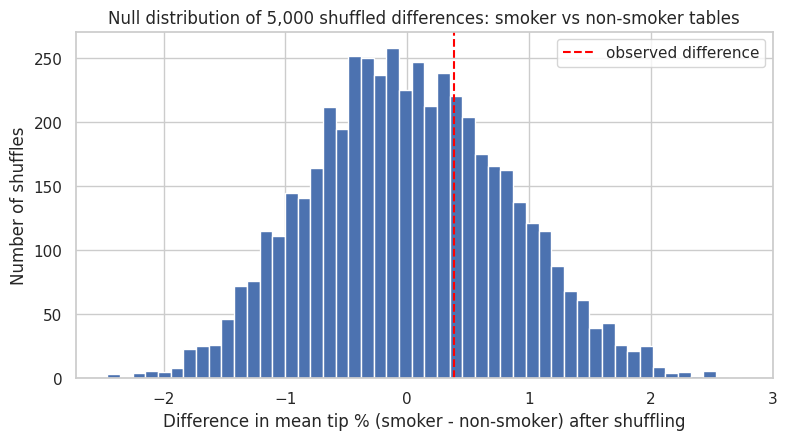

In [11]:
# Goal 3b · Figure · 1 pt
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(null_diffs, bins=50)
# Red dashed line where the real (observed) difference falls
ax.axvline(observed, color="red", linestyle="--", label="observed difference")
ax.legend()
ax.set_xlabel("Difference in mean tip % (smoker - non-smoker) after shuffling")
ax.set_ylabel("Number of shuffles")
ax.set_title("Null distribution of 5,000 shuffled differences: smoker vs non-smoker tables")
plt.show()

**Q2 · 0.75 pt.** Copy the numbers from **your own output above**. Write the conclusion in two sentences that a restaurant manager would understand. Do not use the words *significant*, *null* or *reject*.

Smoker tables (93) left on average 16.32% of the bill and non-smoker tables (151) left 15.93%, a gap of only 0.39 percentage points in favour of smokers. When we shuffled the smoker labels at random 5,000 times, a gap at least this large, in either direction, appeared in about 65% of the shuffles (p = 0.6464). A gap like ours is what pure chance produces all the time, so these 244 tables give the manager no reason to think smoker tables tip differently from non-smoker tables.

**Q3 · 0.5 pt.** A classmate writes: *"the p-value is high, so we proved smokers and non-smokers tip the same."* Two things are wrong with that sentence. Name both.

**1. "proved":** a p-value can never prove anything. It only tells us how often a gap at least as large as ours would appear if the smoker label did not matter (here, in about 65% of the shuffles). It measures how surprising the data are. It is not a proof, and it is not the probability that the two groups tip the same.

**2. "tip the same":** not finding a difference is not the same as showing there is no difference. A high p-value means only that our data are consistent with no difference. A small real difference could still exist, and 244 tables are too few to see it, especially as smoker tips vary a lot (SD 8.51 against 3.99). The data also come from one waiter in one restaurant, so they cannot speak for "smokers and non-smokers" in general.

## 4. The bootstrap

A different question: not *is there a difference*, but *how precisely do we know the mean tip percentage at all?* Resample the data with replacement, recompute the mean, repeat. The middle 95% of those means is the confidence interval.

> **Goal 4a · 1.25 pt.** The first lines of the cell are **ready-made** (down to `boot_means = np.empty(n_boot)`): they store the 244 tip percentages as `all_tips` and make an empty array `boot_means` with 5,000 places. This cell has no seed of its own: it goes on with the `rng` of Part 3.
> Fill in the loop. **Inside** the loop, in place of `...`, write two lines:
> 1. draw a bootstrap sample with `rng.choice(all_tips, size=len(all_tips), replace=True)` and store it as `sample`;
> 2. put the mean of `sample` in place `i` of `boot_means`.
>
> After the loop, find the 95% interval — the 2.5th and the 97.5th percentiles of `boot_means` — and store its two ends as **`lo`** and **`hi`**. Print the mean of `all_tips`, `lo`, `hi` and the width of the interval (`hi - lo`), each rounded to 2 decimals.

In [6]:
# Goal 4a · 1.25 pt
n_boot = 5000
all_tips = tips["tip_pct"].values
boot_means = np.empty(n_boot)
for i in range(n_boot):
    # Resample 244 tables WITH replacement (a table can be drawn more than once)
    sample = rng.choice(all_tips, size=len(all_tips), replace=True)
    boot_means[i] = sample.mean()

# 95% interval: the values that cut off the lowest 2.5% and the highest 2.5%
lo, hi = np.percentile(boot_means, [2.5, 97.5])
print("Mean tip % (all 244 tables):", round(all_tips.mean(), 2))
print("95% interval, lower end (lo):", round(lo, 2))
print("95% interval, upper end (hi):", round(hi, 2))
print("Width of the interval (hi - lo):", round(hi - lo, 2))

Mean tip % (all 244 tables): 16.08
95% interval, lower end (lo): 15.35
95% interval, upper end (hi): 16.91
Width of the interval (hi - lo): 1.57


> **Goal 4b · Figure · 1 pt.** Plot the **bootstrap distribution**: a histogram of the 5,000 values in `boot_means`, with 50 bars. Mark the two ends of the interval with **two vertical lines**, at `lo` and at `hi`. Give the figure an x label, a y label and a title.

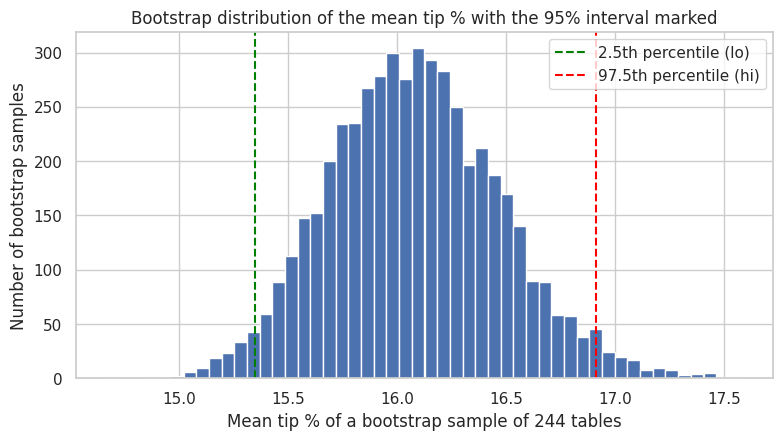

In [18]:
# Goal 4b · Figure · 1 pt
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(boot_means, bins=50)
# Two dashed red lines at the ends of the 95% interval
ax.axvline(lo, color="green", linestyle="--", label="2.5th percentile (lo)")
ax.axvline(hi, color="red", linestyle="--", label="97.5th percentile (hi)")
ax.legend()
ax.set_xlabel("Mean tip % of a bootstrap sample of 244 tables")
ax.set_ylabel("Number of bootstrap samples")
ax.set_title("Bootstrap distribution of the mean tip % with the 95% interval marked")
plt.show()

**Q4 · 0.5 pt.** Copy the numbers from **your own output above**. The interval is about one and a half percentage point wide. What would you have to do to halve that width? Use the rule you found in Lab 6.

The mean tip is 16.08%, and the 95% interval runs from 15.35% to 16.91%, a width of 1.57 percentage points. The rule from Lab 6 is that the spread of a sample mean shrinks with the **square root** of the sample size. To halve the width (divide by 2) we need √(n) to double, so we need **4 times as many tables**: about 4 × 244 = 976 tables instead of 244. Running more bootstrap resamples (for example 20,000 instead of 5,000) would **not** help. It only draws the same distribution more smoothly. Only more real data narrows the interval.

**Q5 · 0.75 pt.** Which of these is a correct reading of your interval, and why are the others wrong?

a) 95% of tables tip within this range.
b) There is a 95% chance the true mean is in this interval.
c) If we repeated the whole study many times, about 95% of the intervals built this way would contain the true mean.

**(c) is correct.** The 95% describes the *method*: if the whole study were repeated many times, and an interval were built this way each time, about 95% of those intervals would contain the true mean tip percentage.

**(a) is wrong** because the interval is about the *mean* tip percentage, not about single tables. Single tables vary far more (the SDs in the first table are 3.99 and 8.51), so most tables tip outside 15.35%–16.91%.

**(b) is wrong** because the true mean is one fixed number, not a random one. This particular interval (15.35% to 16.91%) either contains it or it does not; there is no 95% chance about it. The randomness is in the sampling, so the 95% belongs to the procedure, not to this one interval.

## 5. On your own

Repeat the permutation test for a different question in the same dataset: **do weekend tables tip a different percentage than weekday tables?** Report the observed difference, the p-value, and your conclusion in plain language.

> **Goal 5 · 1.25 pt.** Write your own permutation test in the cell below. **Weekend** tables are the tables with `day` equal to `"Sat"` or `"Sun"`; **weekday** tables are the tables with `day` equal to `"Thur"` or `"Fri"` (the table has no other days). Follow the same steps as in Parts 2 and 3:
> 1. store the `tip_pct` values of the two groups as two arrays, and the observed difference: weekend **minus** weekday;
> 2. start the random part with the line `rng = np.random.default_rng(5)`, so that your numbers can be checked; then shuffle 5,000 times in a loop, as in Part 3;
> 3. compute the two-sided p-value.
>
> Print the number of tables and the mean `tip_pct` of both groups, the observed difference and the p-value. Then write your **conclusion in plain language** in the text cell under the code (the same rule as in Q2: do not use *significant*, *null* or *reject*).

In [8]:
# Goal 5 · 1.25 pt
# 1. The two groups and the observed difference
weekend_mask = tips["day"].isin(["Sat", "Sun"])        # True for Saturday or Sunday
weekend = tips[weekend_mask]["tip_pct"].values          # weekend tables
weekday = tips[~weekend_mask]["tip_pct"].values         # the rest: Thur and Fri

print("Weekend tables:", len(weekend), "| mean tip %:", round(weekend.mean(), 2))
print("Weekday tables:", len(weekday), "| mean tip %:", round(weekday.mean(), 2))

observed_week = weekend.mean() - weekday.mean()         # weekend minus weekday, unrounded
print("Observed difference (weekend - weekday):", round(observed_week, 2))

# 2. The random part: 5,000 shuffles, as in Part 3
rng = np.random.default_rng(5)
pooled_week = np.concatenate([weekend, weekday])
n_weekend = len(weekend)
null_week = np.empty(5000)
for i in range(5000):
    shuffled = rng.permutation(pooled_week)
    null_week[i] = shuffled[:n_weekend].mean() - shuffled[n_weekend:].mean()

# 3. Two-sided p-value
p_week = np.mean(np.abs(null_week) >= abs(observed_week))
print("p-value:", round(p_week, 4))

Weekend tables: 163 | mean tip %: 15.96
Weekday tables: 81 | mean tip %: 16.33
Observed difference (weekend - weekday): -0.37
p-value: 0.6516


**Goal 5 — your conclusion in plain language** *(part of Goal 5)*

Weekend tables (163) left on average 15.96% of the bill and weekday tables (81) left 16.33%, so weekend tables tipped 0.37 percentage points *less*. When we shuffled the weekend/weekday labels at random 5,000 times, a gap at least this large, in either direction, appeared in about 65% of the shuffles (p = 0.6516). A gap this small is the kind that chance alone produces all the time, so for this waiter the data do not show that weekend tables tip a different percentage than weekday tables.

## 6. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** _______________

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] No `...` is left in a loop that you filled in, and your numbers are close to the **Check:** lines
- [ ] Both figures (Goals 3b and 4b) have an x label, a y label, a title and their marked lines
- [ ] Every written answer is filled in — a plot with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab08_Firstname_Lastname.ipynb` — open it once more before you upload it, to be sure it is the **filled** notebook and not the empty starter
- [ ] Report exported as `Lab08_Firstname_Lastname.pdf`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.